In [1]:
import ast
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

datasets = [ 'cartesian', 'flat FAISS', 'hnsw FAISS', 'lsh FAISS']
directories = [ '/home/gap2/Downloads/PPRL-Dev-main/results/matching/D3/',
                '/home/gap2/Downloads/PPRL-Dev-main/results/faiss/D3/matching/flat/',
                '/home/gap2/Downloads/PPRL-Dev-main/results/faiss/D3/matching/hnsw/',
                '/home/gap2/Downloads/PPRL-Dev-main/results/faiss/D3/matching/lsh/' ]

In [2]:
dfs = []

for i in range(len(datasets)):
    for sim in ["cosine", "dice", "jaccard"]:
        df = pd.read_csv(directories[i] + f"{sim}.csv")
        df["similarity"] = sim
        df["dataset"] = datasets[i]
        dfs.append(df)

result = pd.concat(dfs, ignore_index=True)
result['config_dict'] = result['config'].apply(ast.literal_eval)
config_cols = pd.json_normalize(result['config_dict'])
result = result.join(config_cols)
result = result.drop(columns=['config', 'config_dict'])
result

,name,total_matches,similarity_threshold,Precision %,Recall %,F1 %,True Positives,False Positives,True Negatives,False Negatives,similarity,dataset,top_k,attributes,size,offset,num_hashes,hashing_type,salt,qgrams
0,Matching with cosine,126324,0.20,0.87,99.46,1.72,1096,125228,3181,6,cosine,cartesian,NaN,[title],1024,0,1,salted_qgrams,,4
1,Matching with cosine,230324,0.15,0.48,99.55,0.95,1097,229227,3182,5,cosine,cartesian,NaN,[title],1024,0,1,salted_qgrams,,4
2,Matching with cosine,513690,0.10,0.21,99.73,0.43,1099,512591,3184,3,cosine,cartesian,NaN,[title],1024,0,1,salted_qgrams,,4
3,Matching with cosine,66348,0.25,1.64,98.82,3.23,1089,65259,3174,13,cosine,cartesian,NaN,[title],1024,0,1,salted_qgrams,,4
4,Matching with cosine,34848,0.30,3.10,98.09,6.01,1081,33767,3166,21,cosine,cartesian,NaN,[title],1024,0,1,salted_qgrams,,4
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
56539,Matching with jaccard,238,0.75,53.78,11.62,19.10,128,110,2213,974,jaccard,lsh FAISS,10.0,[title],1024,0,32,salted_qgrams,,4
56540,Matching with jaccard,238,0.80,53.78,11.62,19.10,128,110,2213,974,jaccard,lsh FAISS,10.0,[title],1024,0,32,salted_qgrams,,4
56541,Matching with jaccard,238,0.85,53.78,11.62,19.10,128,110,2213,974,jaccard,lsh FAISS,10.0,[title],1024,0,32,salted_qgrams,,4
56542,Matching with jaccard,238,0.90,53.78,11.62,19.10,128,110,2213,974,jaccard,lsh FAISS,10.0,[title],1024,0,32,salted_qgrams,,4


In [3]:
max_f1 = result.loc[result.groupby(['num_hashes','dataset', 'similarity'])['F1 %'].idxmax()]
max_f1

,name,total_matches,similarity_threshold,Precision %,Recall %,F1 %,True Positives,False Positives,True Negatives,False Negatives,similarity,dataset,top_k,attributes,size,offset,num_hashes,hashing_type,salt,qgrams
12,Matching with cosine,1382,0.70,39.36,49.36,43.80,544,838,2629,558,cosine,cartesian,NaN,[title],1024,0,1,salted_qgrams,,4
614,Matching with dice,1721,0.65,34.17,53.36,41.66,588,1133,2673,514,dice,cartesian,NaN,[title],1024,0,1,salted_qgrams,,4
1225,Matching with jaccard,1598,0.50,35.61,51.63,42.15,569,1029,2654,533,jaccard,cartesian,NaN,[title],1024,0,1,salted_qgrams,,4
1833,Matching with cosine,1586,0.50,49.68,71.51,58.63,788,798,2873,314,cosine,flat FAISS,1.0,[title],1024,0,1,salted_qgrams,,4
7904,Matching with dice,178,0.05,48.88,7.89,13.59,87,91,2172,1015,dice,flat FAISS,1.0,[title],1024,0,1,salted_qgrams,,4
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
32034,Matching with dice,237,0.05,53.16,11.43,18.82,126,111,2211,976,dice,hnsw FAISS,1.0,[title],1024,0,32,salted_qgrams,,4
38114,Matching with jaccard,237,0.05,53.16,11.43,18.82,126,111,2211,976,jaccard,hnsw FAISS,1.0,[title],1024,0,32,salted_qgrams,,4
44206,Matching with cosine,2665,0.65,26.15,63.25,37.01,697,1968,2782,405,cosine,lsh FAISS,1.0,[title],1024,0,32,salted_qgrams,,4
50274,Matching with dice,238,0.05,53.78,11.62,19.10,128,110,2213,974,dice,lsh FAISS,1.0,[title],1024,0,32,salted_qgrams,,4


In [4]:
max_f1.value_counts(["dataset", "similarity"])

dataset     similarity
cartesian   cosine        32
            dice          32
            jaccard       32
flat FAISS  cosine        32
            dice          32
            jaccard       32
hnsw FAISS  cosine        32
            dice          32
            jaccard       32
lsh FAISS   cosine        32
            dice          32
            jaccard       32
Name: count, dtype: int64

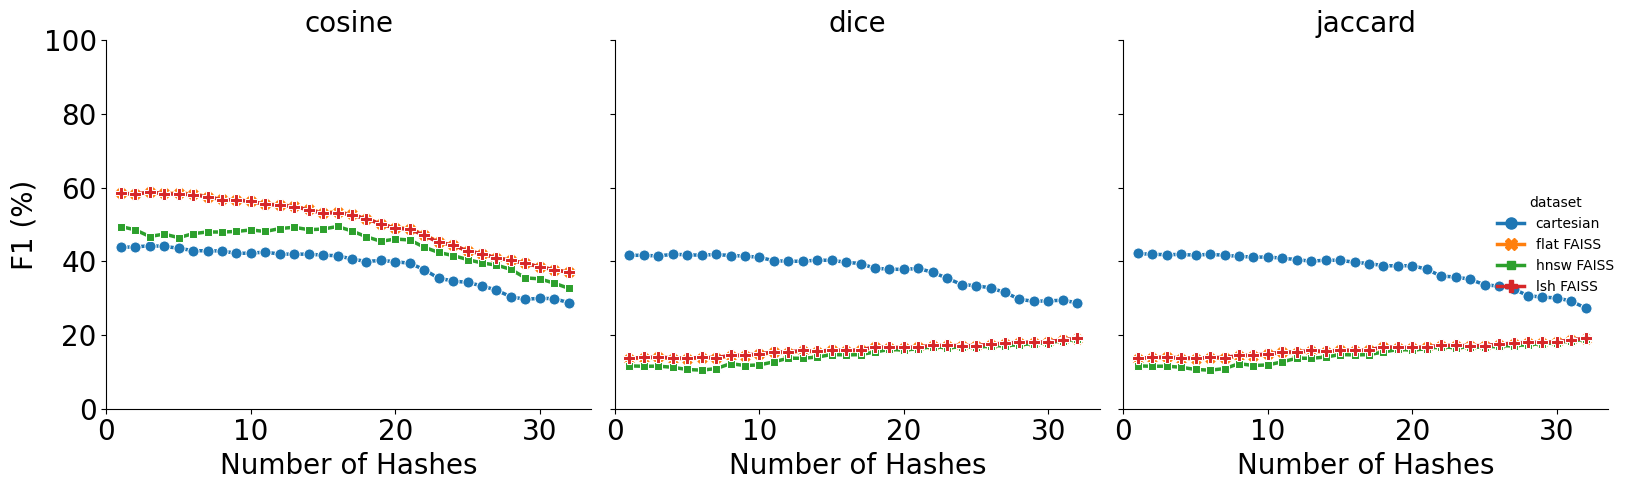

In [5]:
g = sns.relplot(
    data=max_f1,
    x="num_hashes",
    y="F1 %",
    hue="dataset",
    style="dataset",
    markers=True,
    dashes=False,      # solid lines but different markers
    col="similarity",
    kind="line",
    linewidth=2.5,
    markersize=8
)

for ax in g.axes.flat:
    ax.tick_params(axis='both', labelsize=20)
    
g.set_axis_labels("Number of Hashes", "F1 (%)", fontsize=20)
g.set(xlim=(0, None), ylim=(0, 100))
g.set_titles("{col_name}", size=20)

plt.tight_layout()
plt.show()

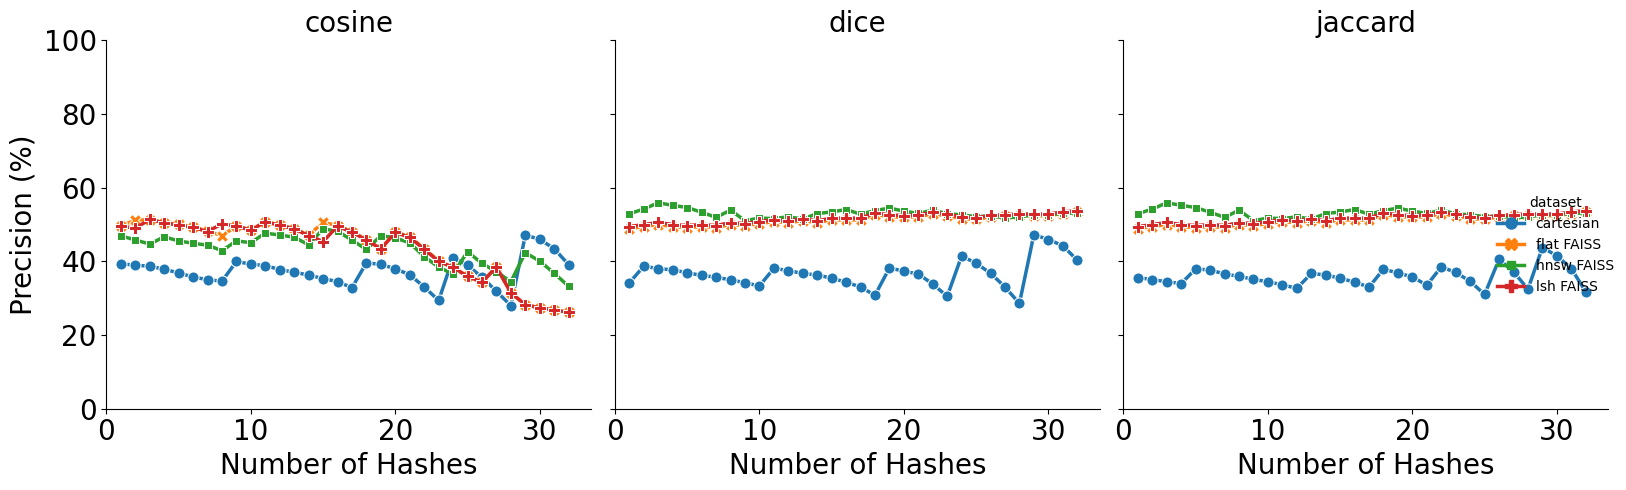

In [6]:
g = sns.relplot(
    data=max_f1,
    x="num_hashes",
    y="Precision %",
    hue="dataset",
    style="dataset",
    markers=True,
    dashes=False,      # solid lines but different markers
    col="similarity",
    kind="line",
    linewidth=2.5,
    markersize=8
)

for ax in g.axes.flat:
    ax.tick_params(axis='both', labelsize=20)
    
g.set_axis_labels("Number of Hashes", "Precision (%)", fontsize=20)
g.set(xlim=(0, None), ylim=(0, 100))
g.set_titles("{col_name}", size=20)

plt.tight_layout()
plt.show()

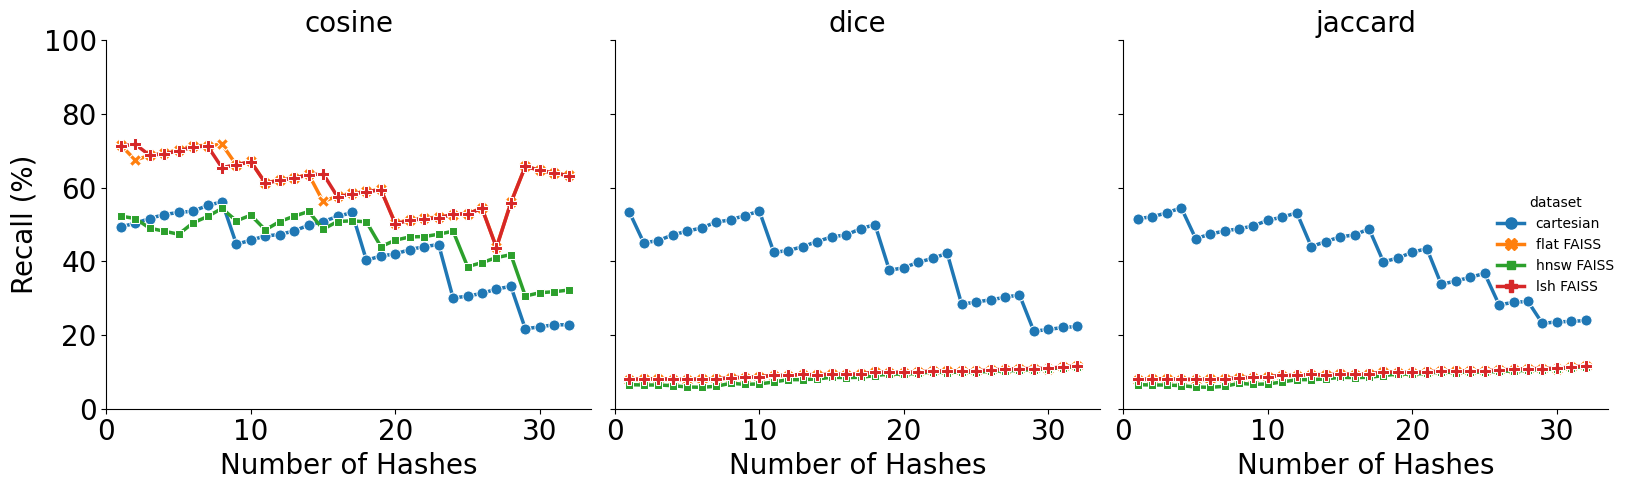

In [7]:
g = sns.relplot(
    data=max_f1,
    x="num_hashes",
    y="Recall %",
    hue="dataset",
    style="dataset",
    markers=True,
    dashes=False,      # solid lines but different markers
    col="similarity",
    kind="line",
    linewidth=2.5,
    markersize=8
)

for ax in g.axes.flat:
    ax.tick_params(axis='both', labelsize=20)
    
g.set_axis_labels("Number of Hashes", "Recall (%)", fontsize=20)
g.set(xlim=(0, None), ylim=(0, 100))
g.set_titles("{col_name}", size=20)

plt.tight_layout()
plt.show()

In [8]:
result['attributes'].value_counts()

attributes
[title]    56544
Name: count, dtype: int64

In [9]:
result['offset'].value_counts()

offset
0    56544
Name: count, dtype: int64

In [10]:
result['hashing_type'].value_counts()

hashing_type
salted_qgrams    56544
Name: count, dtype: int64

In [11]:
result['qgrams'].value_counts()

qgrams
4    56544
Name: count, dtype: int64

In [12]:
result['size'].value_counts()

size
1024    56544
Name: count, dtype: int64

In [13]:
result['num_hashes'].value_counts()

num_hashes
1     1767
2     1767
3     1767
4     1767
5     1767
6     1767
7     1767
8     1767
9     1767
10    1767
11    1767
12    1767
13    1767
14    1767
15    1767
16    1767
17    1767
18    1767
19    1767
20    1767
21    1767
22    1767
23    1767
24    1767
25    1767
26    1767
27    1767
28    1767
29    1767
30    1767
31    1767
32    1767
Name: count, dtype: int64